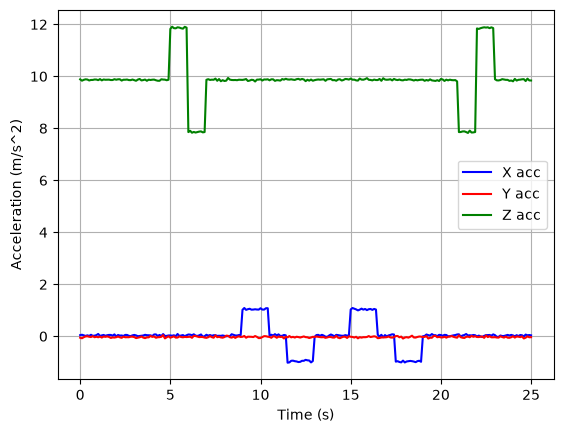

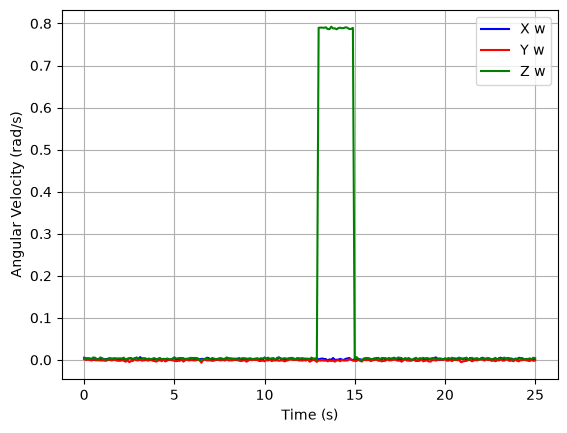

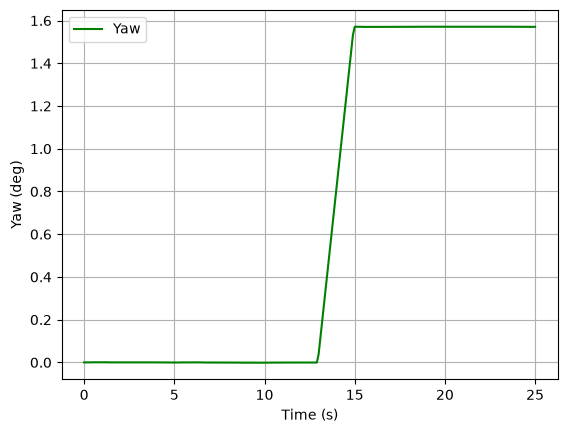

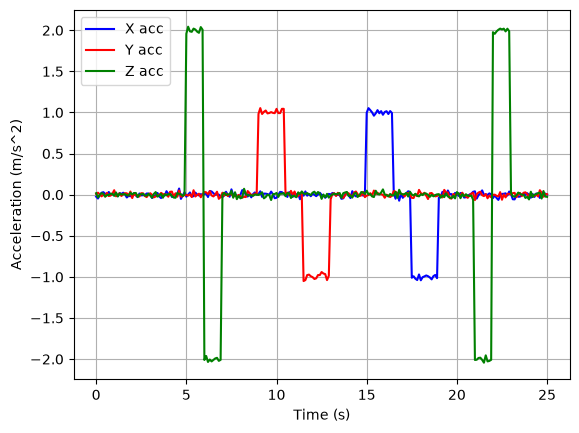

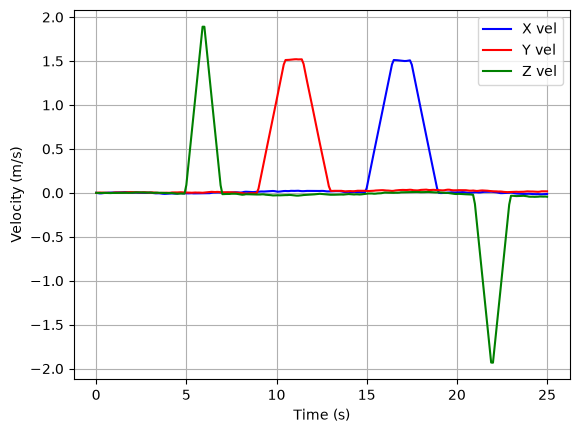

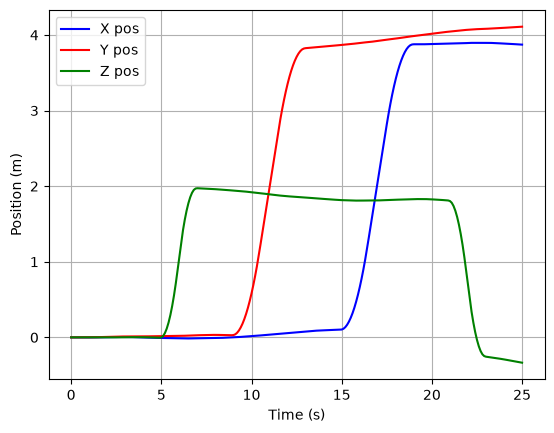

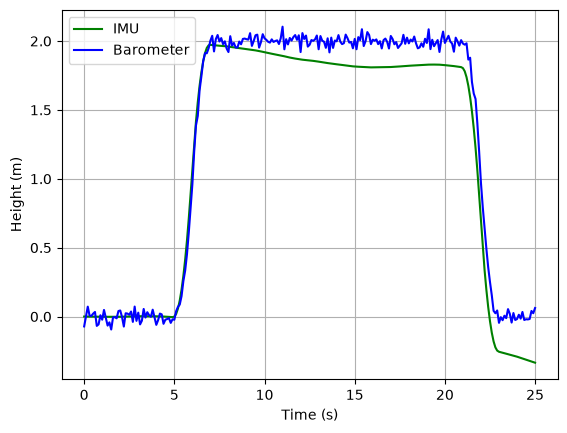

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

dat=pd.read_csv('abc.csv')
datarr= dat.to_numpy()
datarr=np.transpose(datarr)

plt.plot(datarr[0],datarr[1], color='blue', label='X acc')
plt.plot(datarr[0],datarr[2], color='red', label='Y acc')
plt.plot(datarr[0],datarr[3], color='green', label='Z acc')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.grid("True")
plt.legend()
plt.show()

plt.plot(datarr[0],datarr[4], color='blue', label='X w')
plt.plot(datarr[0],datarr[5], color='red', label='Y w')
plt.plot(datarr[0],datarr[6], color='green', label='Z w')
plt.xlabel('Time (s)')
plt.ylabel('Angular Velocity (rad/s)')
plt.grid("True")
plt.legend()
plt.show()

for i in range(1,len(datarr)):
    m= np.mean(datarr[i][ : 50],axis=0)
    s= np.std(datarr[i][ : 50],axis=0)
    val=(datarr[i] < m + 2*s) & (datarr[i] > m - 2*s)
    m= np.mean(datarr[i][val],axis=0)
    datarr[i]=datarr[i]-m
np.set_printoptions(precision=2, suppress=True)

yaw = cumulative_trapezoid(datarr[6], datarr[0], initial=0)
plt.plot(datarr[0],yaw, color='green', label='Yaw')
plt.xlabel('Time (s)')
plt.ylabel('Yaw (deg)')
plt.grid("True")
plt.legend()
plt.show()

accx = datarr[1] * np.sin(yaw) + datarr[2] * np.cos(yaw)
accy = datarr[1] * np.cos(yaw) - datarr[2] * np.sin(yaw)
plt.plot(datarr[0],accx, color='blue', label='X acc')
plt.plot(datarr[0],accy, color='red', label='Y acc')
plt.plot(datarr[0],datarr[3], color='green', label='Z acc')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.grid("True")
plt.legend()
plt.show()

velx = cumulative_trapezoid(accx, datarr[0], initial=0)
vely = cumulative_trapezoid(accy, datarr[0], initial=0)
velz = cumulative_trapezoid(datarr[3], datarr[0], initial=0)
plt.plot(datarr[0],velx, color='blue', label='X vel')
plt.plot(datarr[0],vely, color='red', label='Y vel')
plt.plot(datarr[0],velz, color='green', label='Z vel')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.grid("True")
plt.legend()
plt.show()

posx = cumulative_trapezoid(velx, datarr[0], initial=0)
posy = cumulative_trapezoid(vely, datarr[0], initial=0)
posz = cumulative_trapezoid(velz, datarr[0], initial=0)
plt.plot(datarr[0],posx, color='blue', label='X pos')
plt.plot(datarr[0],posy, color='red', label='Y pos')
plt.plot(datarr[0],posz, color='green', label='Z pos')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.grid("True")
plt.legend()
plt.show()

plt.plot(datarr[0],posz, color='green', label='IMU')
plt.plot(datarr[0],datarr[7], color='blue', label='Barometer')
plt.xlabel('Time (s)')
plt.ylabel('Height (m)')
plt.grid("True")
plt.legend()
plt.show()
